<a href="https://colab.research.google.com/github/kk12102006/DAV/blob/main/LAB%20PROGRAM%206.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.decomposition import PCA

In [3]:
data={
    'Study_Hours':[2,4,6,8,10,3,7,9],
    'Attendence':[50,60,70,80,90,55,75,85],
    'Assignment_Score':[40,50,60,75,90,45,70,85],
    'Internal_Marks':[35,45,55,70,88,40,65,82]
}

In [4]:
df=pd.DataFrame(data)
print("Original Dataset")
print(df)

Original Dataset
   Study_Hours  Attendence  Assignment_Score  Internal_Marks
0            2          50                40              35
1            4          60                50              45
2            6          70                60              55
3            8          80                75              70
4           10          90                90              88
5            3          55                45              40
6            7          75                70              65
7            9          85                85              82


In [6]:
normalizer=MinMaxScaler()
normalizeddata=normalizer.fit_transform(df)

In [8]:
normalized_df=pd.DataFrame(
    normalizeddata,
    columns=df.columns
)
print("Normalized Dataset")
print(normalized_df.round(2))

Normalized Dataset
   Study_Hours  Attendence  Assignment_Score  Internal_Marks
0         0.00        0.00               0.0            0.00
1         0.25        0.25               0.2            0.19
2         0.50        0.50               0.4            0.38
3         0.75        0.75               0.7            0.66
4         1.00        1.00               1.0            1.00
5         0.12        0.12               0.1            0.09
6         0.62        0.62               0.6            0.57
7         0.88        0.88               0.9            0.89


In [10]:
scaler=StandardScaler()
standradizeddata=scaler.fit_transform(df)

In [29]:
standardized_df=pd.DataFrame(
    standradizeddata,
    columns=df.columns
)
print("Standardized Dataset")
print(standardized_df.round(4))
print("Mean of Standardized Features:")
print(standardized_df.mean().round(4))
print("Standard Deviation of Standardized Features:")
print(standardized_df.std(ddof=0).round(4))

Standardized Dataset
   Study_Hours  Attendence  Assignment_Score  Internal_Marks
0      -1.5206     -1.5206           -1.4009         -1.3690
1      -0.7833     -0.7833           -0.8262         -0.8214
2      -0.0461     -0.0461           -0.2514         -0.2738
3       0.6912      0.6912            0.6107          0.5476
4       1.4284      1.4284            1.4728          1.5332
5      -1.1519     -1.1519           -1.1136         -1.0952
6       0.3225      0.3225            0.3233          0.2738
7       1.0598      1.0598            1.1854          1.2047
Mean of Standardized Features:
Study_Hours         0.0
Attendence          0.0
Assignment_Score    0.0
Internal_Marks      0.0
dtype: float64
Standard Deviation of Standardized Features:
Study_Hours         1.0
Attendence          1.0
Assignment_Score    1.0
Internal_Marks      1.0
dtype: float64


In [12]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(df)

In [27]:
pca=PCA(n_components=2)
pca_data=pca.fit_transform(X_scaled)
pca_df=pd.DataFrame(pca_data,columns=['Principal_Component_1','Principal_Component_2'])


In [20]:
print("PCA Transformed Dataset")
print(pca_df.round(2))

PCA Transformed Dataset
   Principal_Component_1  Principal_Component_2
0                  -2.91                   0.14
1                  -1.61                  -0.04
2                  -0.31                  -0.22
3                   1.27                  -0.12
4                   2.93                   0.08
5                  -2.26                   0.05
6                   0.62                  -0.03
7                   2.25                   0.14


In [15]:
print("Explained Variance Ratio")
print(pca.explained_variance_ratio_.round(4))

Explained Variance Ratio
[0.9965 0.0034]


In [16]:
print("Total Variance Retained")
print(round(pca.explained_variance_ratio_.sum()*100,2),"%")

Total Variance Retained
99.99 %


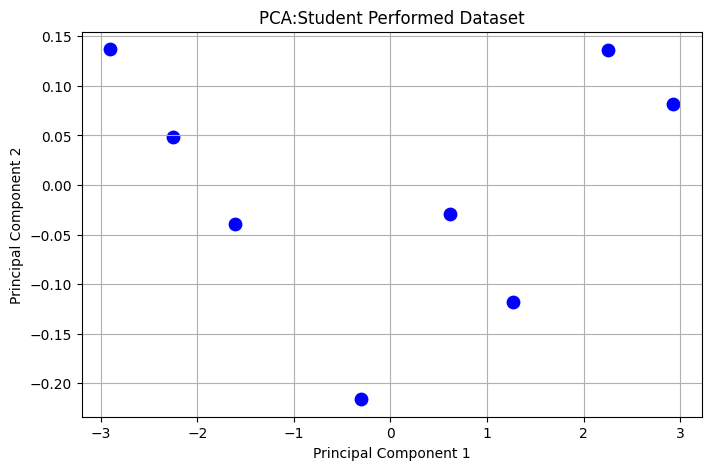

In [22]:
plt.figure(figsize=(8,5))
plt.scatter(
    pca_df["Principal_Component_1"],
    pca_df["Principal_Component_2"],
    color="blue",
    s=80
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA:Student Performed Dataset")

plt.grid(True)
plt.show()

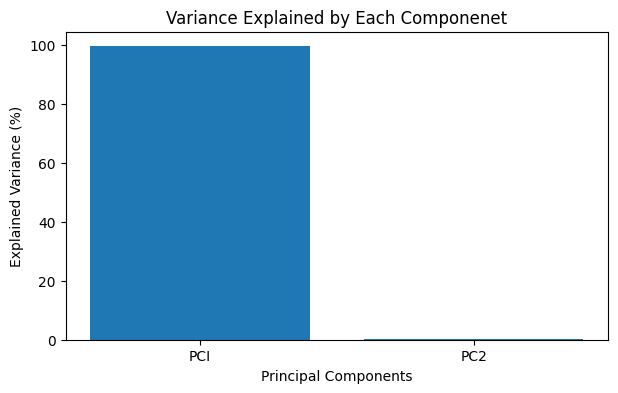

In [24]:
plt.figure(figsize=(7,4))
components=['PCI','PC2']
plt.bar(
    components,
    pca.explained_variance_ratio_*100
)
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance (%)')
plt.title("Variance Explained by Each Componenet")
plt.show()